In [1]:
import fastf1
import matplotlib.pyplot as plt
plt.style.use('dark_background')

fastf1.Cache.configure(cache_dir='cache')
session = fastf1.get_session(2023, 'Bahrain', 'R') 
session.load()

laps = session.laps
laps['LapTimeSeconds'] = laps['LapTime'].dt.total_seconds()
driver_laps = laps[laps['Driver'] == 'VER']

core           INFO 	Loading data for Bahrain Grand Prix - Race [v3.9.0]
req            INFO 	Using cached data for session_info
req            INFO 	Using cached data for driver_info
req            INFO 	Using cached data for session_status_data
req            INFO 	Using cached data for lap_count
req            INFO 	Using cached data for track_status_data
req            INFO 	Using cached data for _extended_timing_data
req            INFO 	Using cached data for timing_app_data
core           INFO 	Processing timing data...
req            INFO 	Using cached data for car_data
req            INFO 	Using cached data for position_data
req            INFO 	Using cached data for weather_data
req            INFO 	Using cached data for race_control_messages
core           INFO 	Finished loading data for 20 drivers: ['1', '11', '14', '55', '44', '18', '63', '77', '10', '23', '22', '2', '20', '21', '27', '24', '4', '31', '16', '81']


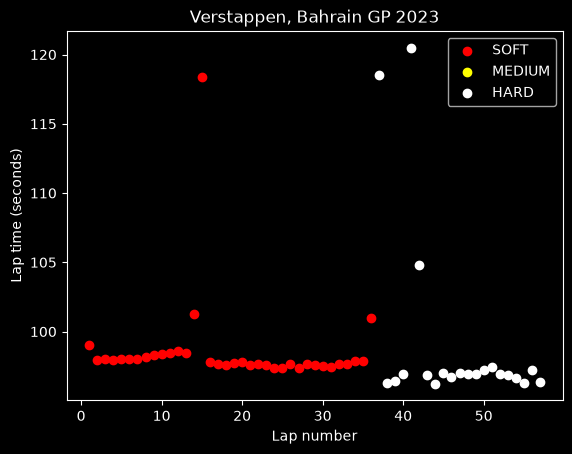

In [2]:
compound_colours = {'SOFT': 'red', 'MEDIUM': 'yellow', 'HARD': 'white'}

for compound, colour in compound_colours.items():
    data = driver_laps[driver_laps['Compound'] == compound]
    plt.scatter(data['LapNumber'], data['LapTimeSeconds'], color=colour, 
label=compound)

plt.xlabel('Lap number')
plt.ylabel('Lap time (seconds)')
plt.title('Verstappen, Bahrain GP 2023')
plt.legend()
plt.show()


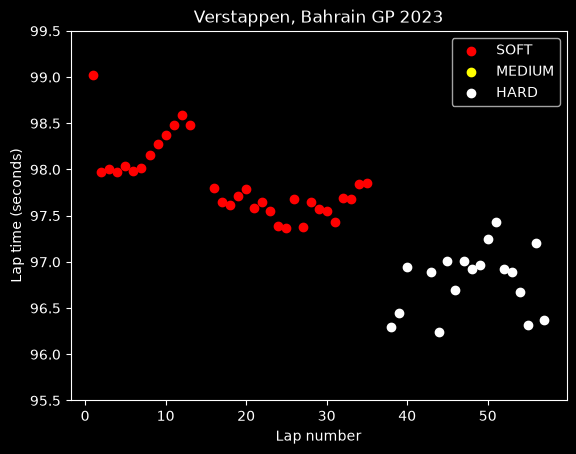

In [3]:
compound_colours = {'SOFT': 'red', 'MEDIUM': 'yellow', 'HARD': 'white'}

for compound, colour in compound_colours.items():
    data = driver_laps[driver_laps['Compound'] == compound]
    plt.scatter(data['LapNumber'], data['LapTimeSeconds'], color=colour, 
label=compound)

plt.xlabel('Lap number')
plt.ylabel('Lap time (seconds)')
plt.title('Verstappen, Bahrain GP 2023')
plt.legend()
plt.ylim(95.5, 99.5)
plt.savefig('figures/Verstappen_Bahrain_2023_laps.png', dpi = 300, bbox_inches = 'tight')
plt.show()

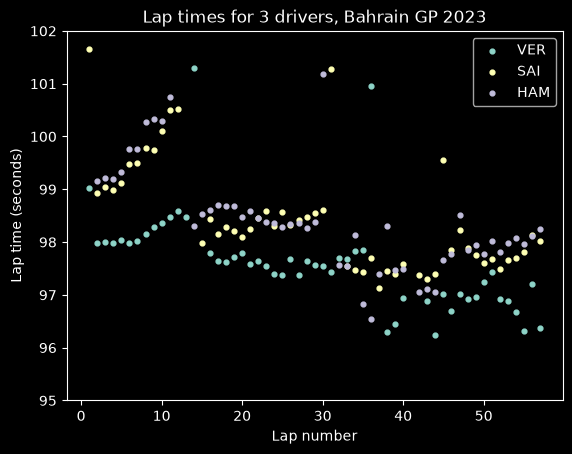

In [4]:
drivers = ['VER', 'SAI', 'HAM']

for driver in drivers:
    data = laps[laps['Driver'] == driver]
    plt.scatter(data['LapNumber'], data['LapTimeSeconds'], label=driver, s=12)

plt.xlabel('Lap number')
plt.ylabel('Lap time (seconds)')
plt.title('Lap times for 3 drivers, Bahrain GP 2023')
plt.legend()
plt.ylim(95, 102)
plt.savefig('figures/3_drivers_Bahrain_2023_laps.png', dpi=300, bbox_inches='tight')
plt.show()

In [5]:
for driver in ['VER', 'SAI', 'HAM']:
    d = laps[laps['Driver'] == driver]
    pit_laps = d[d['PitInTime'].notna()]['LapNumber'].astype(int).tolist()
    compounds = d.groupby('Stint')['Compound'].first().tolist()
    print(driver, len(d), 'laps, pitted on laps', pit_laps, compounds)

VER 57 laps, pitted on laps [14, 36] ['SOFT', 'SOFT', 'HARD']
SAI 57 laps, pitted on laps [13, 31] ['SOFT', 'HARD', 'HARD']
HAM 57 laps, pitted on laps [12, 30] ['SOFT', 'HARD', 'HARD']


In [6]:
for driver in ['VER', 'SAI', 'HAM']:
    d = laps[(laps['Driver'] == driver) & (laps['TrackStatus'] == '1') & laps['PitInTime'].isna()
             & laps['PitOutTime'].isna() & (laps['LapNumber'] > 1)]
    for stint, s in d.groupby('Stint'):
        print(driver, int(stint), s['Compound'].iloc[0],
              round(s['LapTimeSeconds'].head(3).mean(), 2),
              round(s['LapTimeSeconds'].tail(3).mean(), 2))

VER 1 SOFT 98.01 98.52
VER 2 SOFT 97.69 97.79
VER 3 HARD 96.56 96.63
SAI 1 SOFT 99.05 100.38
SAI 2 HARD 98.19 98.54
SAI 3 HARD 97.49 97.99
HAM 1 SOFT 99.25 100.45
HAM 2 HARD 98.48 98.34
HAM 3 HARD 97.75 98.11


In [7]:
table_cols = ['LapNumber', 'LapTimeSeconds', 'Position', 'Stint', 'Compound', 'TrackStatus', 'PitInTime', 'PitOutTime']
laps[laps['Driver'] == 'VER'][table_cols]

,LapNumber,LapTimeSeconds,Position,Stint,Compound,TrackStatus,PitInTime,PitOutTime
0,1.0,99.019,1.0,1.0,SOFT,12,NaT,NaT
1,2.0,97.974,1.0,1.0,SOFT,12,NaT,NaT
2,3.0,98.006,1.0,1.0,SOFT,1,NaT,NaT
3,4.0,97.976,1.0,1.0,SOFT,1,NaT,NaT
4,5.0,98.035,1.0,1.0,SOFT,1,NaT,NaT
5,6.0,97.986,1.0,1.0,SOFT,1,NaT,NaT
6,7.0,98.021,1.0,1.0,SOFT,1,NaT,NaT
7,8.0,98.154,1.0,1.0,SOFT,1,NaT,NaT
8,9.0,98.278,1.0,1.0,SOFT,1,NaT,NaT
9,10.0,98.369,1.0,1.0,SOFT,1,NaT,NaT


In [8]:
laps[laps['Driver'] == 'SAI'][table_cols]

,LapNumber,LapTimeSeconds,Position,Stint,Compound,TrackStatus,PitInTime,PitOutTime
872,1.0,101.659,4.0,1.0,SOFT,12,NaT,NaT
873,2.0,98.933,4.0,1.0,SOFT,21,NaT,NaT
874,3.0,99.042,4.0,1.0,SOFT,1,NaT,NaT
875,4.0,98.985,4.0,1.0,SOFT,1,NaT,NaT
876,5.0,99.128,4.0,1.0,SOFT,1,NaT,NaT
877,6.0,99.474,4.0,1.0,SOFT,1,NaT,NaT
878,7.0,99.502,4.0,1.0,SOFT,1,NaT,NaT
879,8.0,99.779,4.0,1.0,SOFT,1,NaT,NaT
880,9.0,99.744,4.0,1.0,SOFT,1,NaT,NaT
881,10.0,100.102,4.0,1.0,SOFT,1,NaT,NaT


In [9]:
laps[laps['Driver'] == 'HAM'][table_cols]

,LapNumber,LapTimeSeconds,Position,Stint,Compound,TrackStatus,PitInTime,PitOutTime
815,1.0,102.288,5.0,1.0,SOFT,12,NaT,NaT
816,2.0,99.166,5.0,1.0,SOFT,21,NaT,NaT
817,3.0,99.220,5.0,1.0,SOFT,1,NaT,NaT
818,4.0,99.198,5.0,1.0,SOFT,1,NaT,NaT
819,5.0,99.335,5.0,1.0,SOFT,1,NaT,NaT
820,6.0,99.756,5.0,1.0,SOFT,1,NaT,NaT
821,7.0,99.757,5.0,1.0,SOFT,1,NaT,NaT
822,8.0,100.267,5.0,1.0,SOFT,1,NaT,NaT
823,9.0,100.323,5.0,1.0,SOFT,1,NaT,NaT
824,10.0,100.289,5.0,1.0,SOFT,1,NaT,NaT


In [10]:
ver = laps[laps['Driver'] == 'VER']
clean = ver[(ver['TrackStatus'] == '1') & ver['PitInTime'].isna() & ver['PitOutTime'].isna() & (ver['LapNumber'] > 1)]
print('Verstappen clean laps:', clean['LapTimeSeconds'].min(), 'to', clean['LapTimeSeconds'].max())

Verstappen clean laps: 96.236 to 98.591
